In [1]:
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True)

df = housing.frame

In [2]:
df.shape
df.info()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [3]:
#  The dataset contains 20,640 rows and 9 columns. All columns have the float64 data type, and no missing values were found.

#  Although all columns share the same data type, they represent different kinds of variables, 
# including numerical measurements and geographical coordinates.

#  Next, I will check for duplicate rows to further investigate the dataset's integrity.

In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
# The dataset contains no exact duplicate rows.

In [6]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


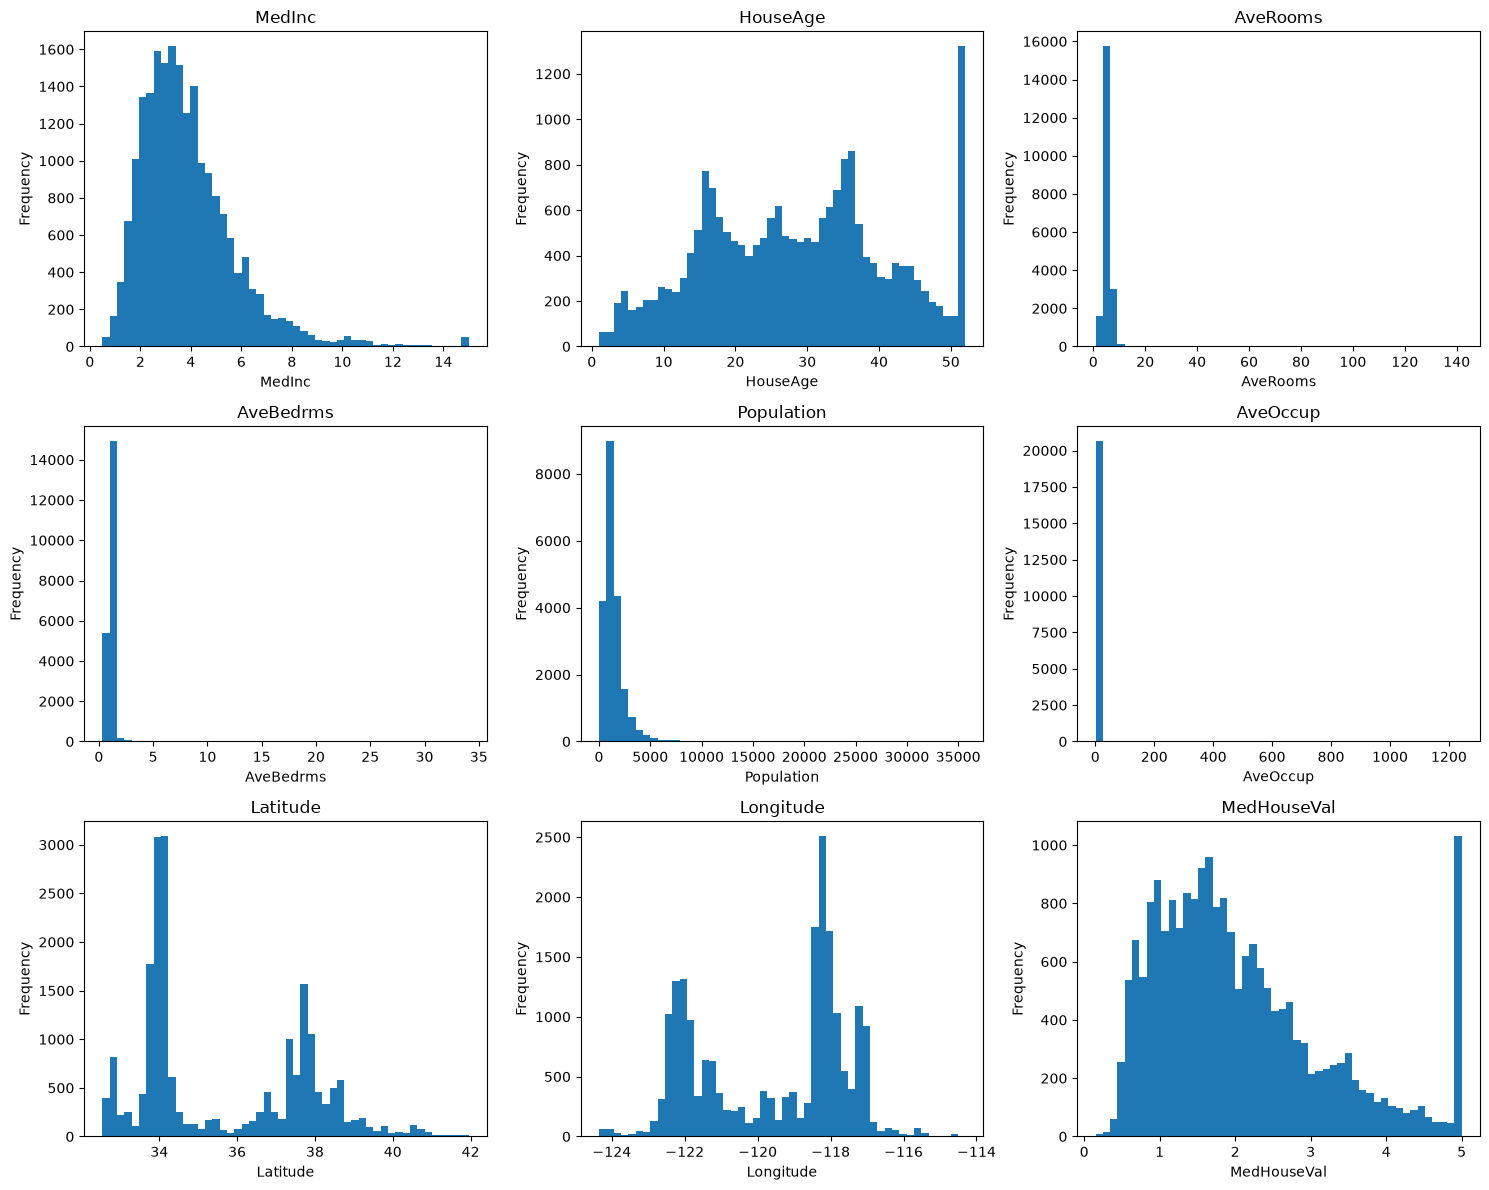

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for col, ax in zip(df.columns, axes.flat):
    ax.hist(df[col], bins=50)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [8]:
# MedInc: right skewed with no visible capping
# HouseAge: bimodal with potential capping
# AveRooms: potential right skew with no visible capping
# AveBedrms: potential right skew with no visible capping
# Population: right skew with no visible capping
# AveOccup: potential right skew with no potentail capping
# I will skip and map Latitude and Longitude later on
# MedHouseVal: right skew with potential capping

In [9]:
# Now will do log histograms to visibly confirm shapes of the histograms above

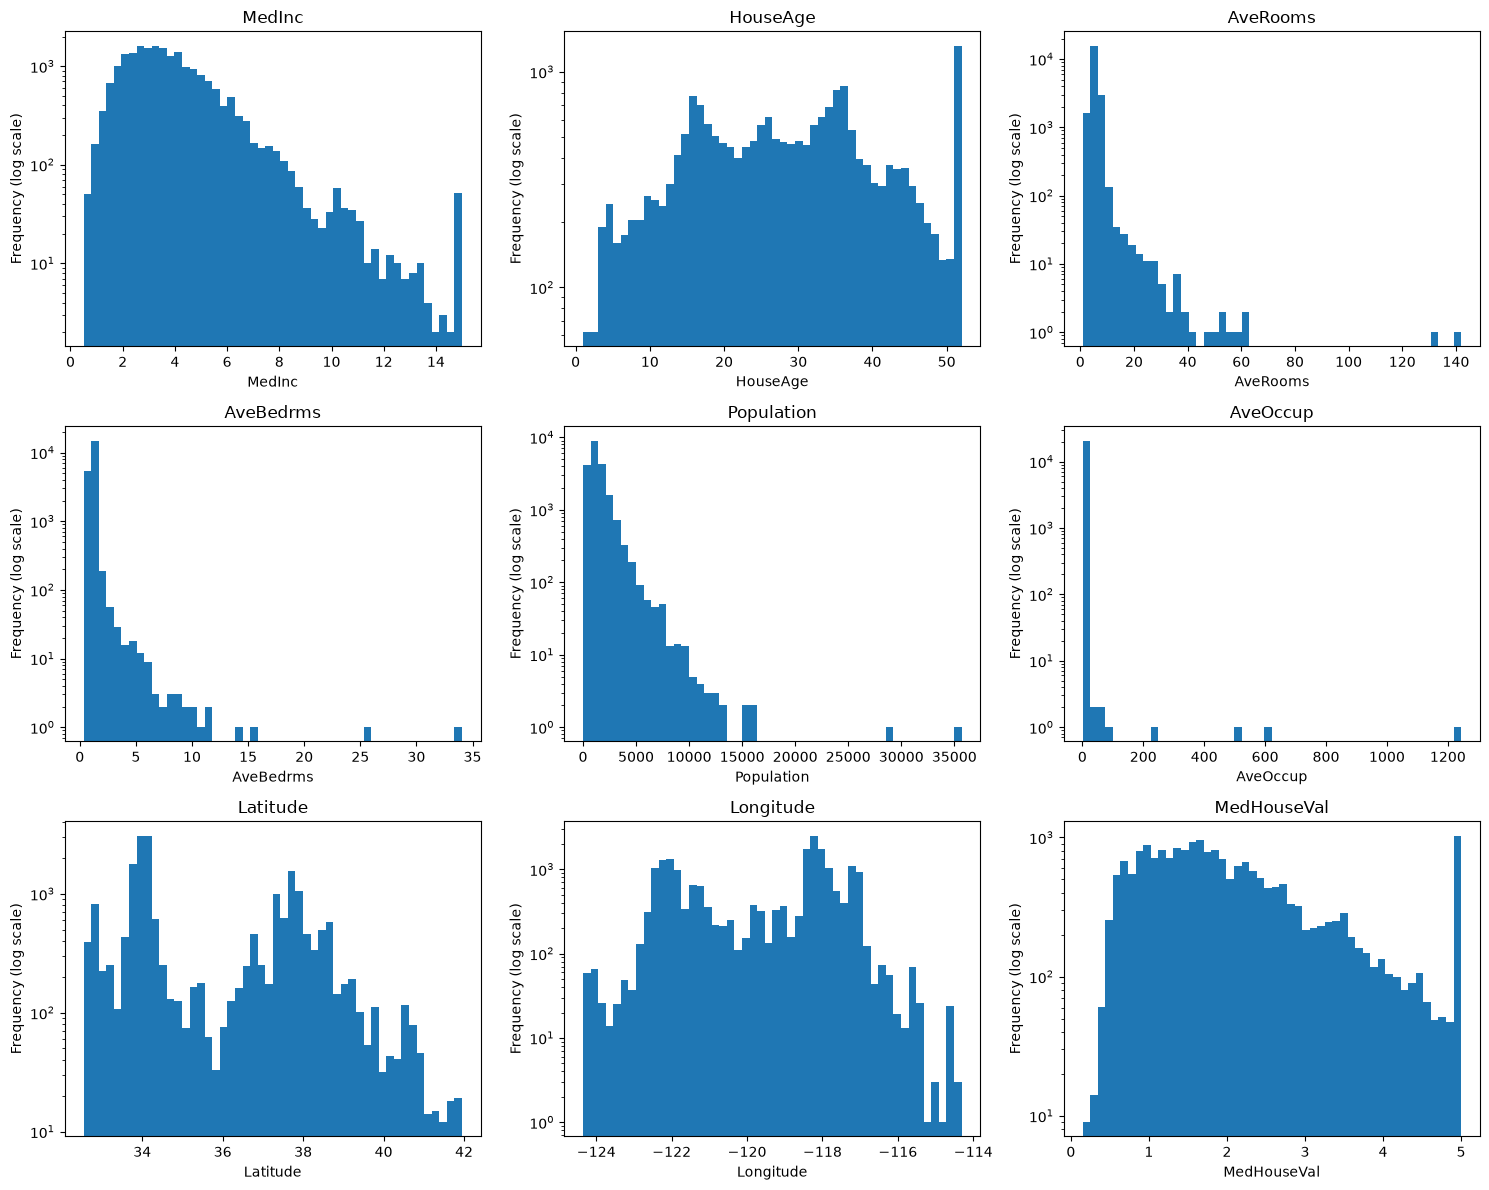

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for col, ax in zip(df.columns, axes.flat):
    ax.hist(df[col], bins=50)
    ax.set_yscale("log")
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency (log scale)")

plt.tight_layout()
plt.show()

In [11]:
# The log-scaled histograms make the low-frequency regions of the distributions easier to inspect.
# Tails confirmed.
# I will now investigate the potential capped values identified during the initial histogram analysis.

In [12]:
df["HouseAge"].value_counts().sort_index(ascending=False).head(10)

HouseAge
52.0    1273
51.0      48
50.0     136
49.0     134
48.0     177
47.0     198
46.0     245
45.0     294
44.0     356
43.0     353
Name: count, dtype: int64

In [13]:
# HouseAge has potential capping at 52, with 1273 observations at this value.

In [14]:
df["MedHouseVal"].value_counts().sort_index(ascending=False).head(10)

MedHouseVal
5.00001    965
5.00000     27
4.99100      1
4.99000      1
4.98800      1
4.98700      1
4.98600      1
4.98400      1
4.97600      1
4.97400      1
Name: count, dtype: int64

In [15]:
# MedHouseVal has potential capping at 5.00001, with 965 observations at this value.

In [16]:
# Next, I will use boxplots to identify potential outliers in each feature.

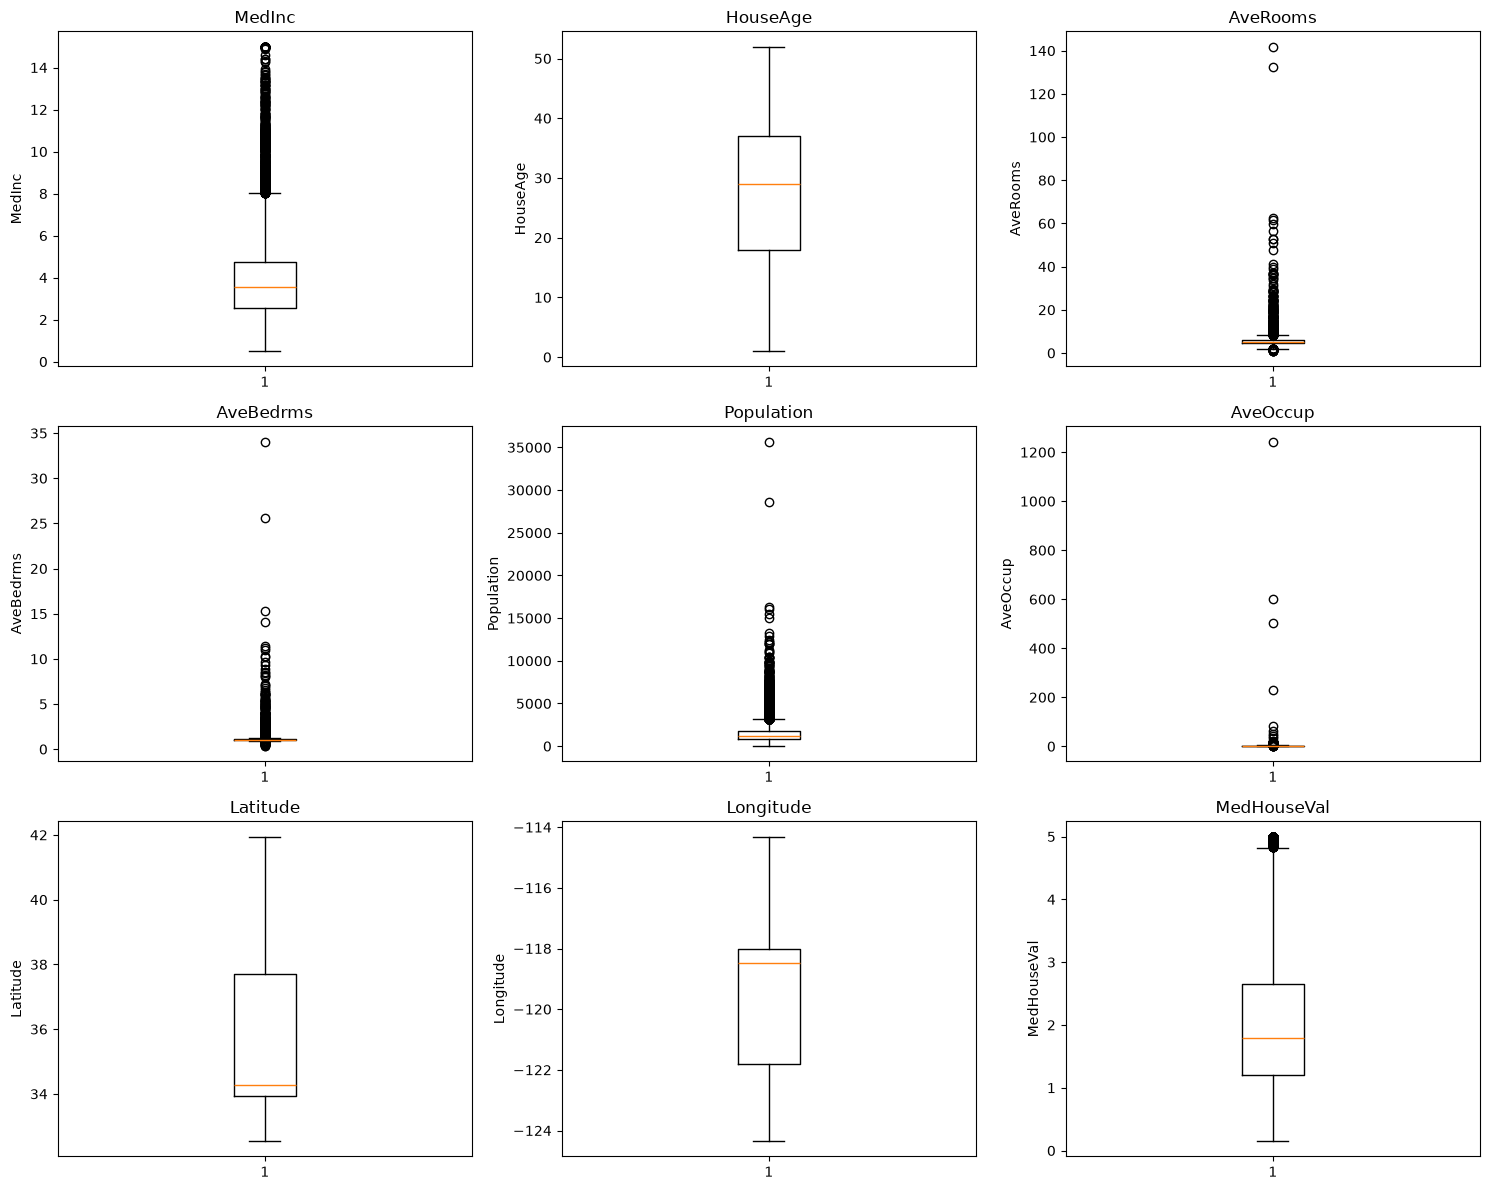

In [17]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for col, ax in zip(df.columns, axes.flat):
    ax.boxplot(df[col])
    ax.set_title(col)
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

In [18]:
# The boxplots show potential outliers in MedInc, AveRooms, AveBedrms, Population, AveOccup, and MedHouseVal. 
# I will investigate whether these values are valid or require further attention.

In [19]:
df.nlargest(10, "MedInc")

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
1566,15.0001,2.0,22.222222,2.222222,25.0,2.777778,37.74,-121.96,3.50000
4352,15.0001,37.0,8.659574,1.425532,100.0,2.127660,34.10,-118.37,5.00001
4604,15.0001,52.0,8.444954,1.100917,693.0,3.178899,34.06,-118.33,5.00001
4605,15.0001,52.0,8.483019,0.962264,813.0,3.067925,34.07,-118.33,5.00001
4606,15.0001,52.0,9.204969,1.062112,531.0,3.298137,34.07,-118.33,5.00001
4626,15.0001,52.0,7.958333,0.833333,457.0,3.808333,34.06,-118.32,5.00001
4678,15.0001,52.0,8.780612,0.994898,688.0,3.510204,34.08,-118.34,5.00001
5242,15.0001,32.0,8.002869,1.080344,1567.0,2.248207,34.11,-118.40,5.00001
5247,15.0001,36.0,9.368263,1.173653,862.0,2.580838,34.09,-118.44,5.00001
5248,15.0001,46.0,8.365591,0.967742,238.0,2.559140,34.08,-118.43,5.00001


In [20]:
df.nlargest(10, "AveRooms")

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
1914,1.8750,33.0,141.909091,25.636364,30.0,2.727273,38.91,-120.10,5.00001
1979,4.6250,34.0,132.533333,34.066667,36.0,2.400000,38.80,-120.08,1.62500
12447,1.6154,17.0,62.422222,14.111111,83.0,1.844444,33.97,-114.49,0.87500
1913,4.0714,19.0,61.812500,11.000000,112.0,2.333333,39.01,-120.06,4.37500
11862,2.6250,25.0,59.875000,15.312500,28.0,1.750000,40.27,-121.25,0.67500
1912,4.9750,16.0,56.269231,10.153846,54.0,2.076923,39.01,-120.16,2.06300
9676,3.2431,14.0,52.848214,11.410714,265.0,2.366071,37.64,-119.02,2.21400
11707,1.1912,22.0,52.690476,8.857143,98.0,2.333333,39.15,-120.06,1.70000
2395,3.8750,23.0,50.837838,10.270270,64.0,1.729730,37.12,-119.34,1.25000
1240,3.1250,11.0,47.515152,11.181818,82.0,2.484848,38.42,-120.19,0.77500


In [21]:
df.nlargest(10, "AveBedrms")

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
1979,4.6250,34.0,132.533333,34.066667,36.0,2.400000,38.80,-120.08,1.62500
1914,1.8750,33.0,141.909091,25.636364,30.0,2.727273,38.91,-120.10,5.00001
11862,2.6250,25.0,59.875000,15.312500,28.0,1.750000,40.27,-121.25,0.67500
12447,1.6154,17.0,62.422222,14.111111,83.0,1.844444,33.97,-114.49,0.87500
9676,3.2431,14.0,52.848214,11.410714,265.0,2.366071,37.64,-119.02,2.21400
1240,3.1250,11.0,47.515152,11.181818,82.0,2.484848,38.42,-120.19,0.77500
1913,4.0714,19.0,61.812500,11.000000,112.0,2.333333,39.01,-120.06,4.37500
2395,3.8750,23.0,50.837838,10.270270,64.0,1.729730,37.12,-119.34,1.25000
1912,4.9750,16.0,56.269231,10.153846,54.0,2.076923,39.01,-120.16,2.06300
1102,2.4028,17.0,31.777778,9.703704,47.0,1.740741,40.06,-121.54,0.67500


In [22]:
df.nlargest(10, "Population")

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
15360,2.5729,14.0,5.270497,1.010484,35682.0,7.482072,33.35,-117.42,1.344
9880,2.3087,11.0,5.364518,1.059684,28566.0,4.696810,36.64,-121.79,1.188
13139,4.9516,3.0,7.338559,1.159015,16305.0,3.043113,38.43,-121.44,1.537
10309,7.4947,4.0,7.311043,1.054346,16122.0,3.106957,33.89,-117.74,3.663
6057,6.0191,8.0,6.347327,1.047525,15507.0,3.070693,34.03,-117.78,2.539
6066,6.6288,7.0,6.802554,1.026277,15037.0,3.692780,34.04,-117.87,3.397
12215,4.5841,4.0,7.006453,1.142429,13251.0,3.053929,33.52,-117.12,2.123
9019,8.0137,9.0,7.734673,1.041211,12873.0,3.274739,34.16,-118.78,3.992
17413,2.7377,29.0,6.276716,1.101911,12427.0,4.397381,34.70,-120.59,0.283
922,8.4045,7.0,7.635234,1.044042,12203.0,3.297217,37.53,-121.92,4.511


In [23]:
df.nlargest(10, "AveOccup")

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
19006,10.2264,45.0,3.166667,0.833333,7460.0,1243.333333,38.32,-121.98,1.37500
3364,5.5179,36.0,5.142857,1.142857,4198.0,599.714286,40.41,-120.51,0.67500
16669,4.2639,46.0,9.076923,1.307692,6532.0,502.461538,35.32,-120.70,3.50000
13034,6.1359,52.0,8.275862,1.517241,6675.0,230.172414,38.69,-121.15,2.25000
9172,4.2391,5.0,5.123810,0.933333,8733.0,83.171429,34.47,-118.59,1.54600
12104,1.6250,8.0,7.600000,0.950000,1275.0,63.750000,33.97,-117.33,1.62500
16420,5.7485,26.0,5.366667,0.900000,1542.0,51.400000,37.89,-121.29,1.62500
8874,9.3370,52.0,7.285714,1.214286,1154.0,41.214286,34.06,-118.45,5.00001
13366,4.2578,36.0,5.258824,1.117647,2886.0,33.952941,33.94,-117.63,1.83300
5986,1.8750,52.0,4.500000,1.206349,2688.0,21.333333,34.10,-117.71,2.12500


In [24]:
df.nlargest(10, "MedHouseVal")

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
89,1.2434,52.0,2.929412,0.917647,396.0,4.658824,37.80,-122.27,5.00001
459,1.1696,52.0,2.436000,0.944000,1349.0,5.396000,37.87,-122.25,5.00001
493,7.8521,52.0,7.794393,1.051402,517.0,2.415888,37.86,-122.24,5.00001
494,9.3959,52.0,7.512097,0.955645,1366.0,2.754032,37.85,-122.24,5.00001
509,7.8772,52.0,8.282548,1.049861,947.0,2.623269,37.83,-122.23,5.00001
510,11.8603,39.0,7.911111,0.984127,808.0,2.565079,37.82,-122.22,5.00001
511,13.4990,42.0,8.928358,1.000000,1018.0,3.038806,37.82,-122.22,5.00001
512,12.2138,52.0,9.210227,1.039773,1001.0,2.843750,37.82,-122.23,5.00001
514,12.3804,52.0,9.122715,1.033943,1192.0,3.112272,37.82,-122.23,5.00001
517,8.7477,52.0,9.000000,1.134078,556.0,3.106145,37.82,-122.23,5.00001


In [25]:
# Found extreme AveRooms and AveRooms values, often in districts with small population.
# Found unusually high AveOccup values that may indicate data quality issues.
# No observations were removed.

In [26]:
df[df["AveBedrms"] > df["AveRooms"]]

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal


In [27]:
# Did a logical check, everything is OK.

In [28]:
# The target is MedHouseVal. Now will plot every feature against the target.
# The goal is to see their relationship at a time.

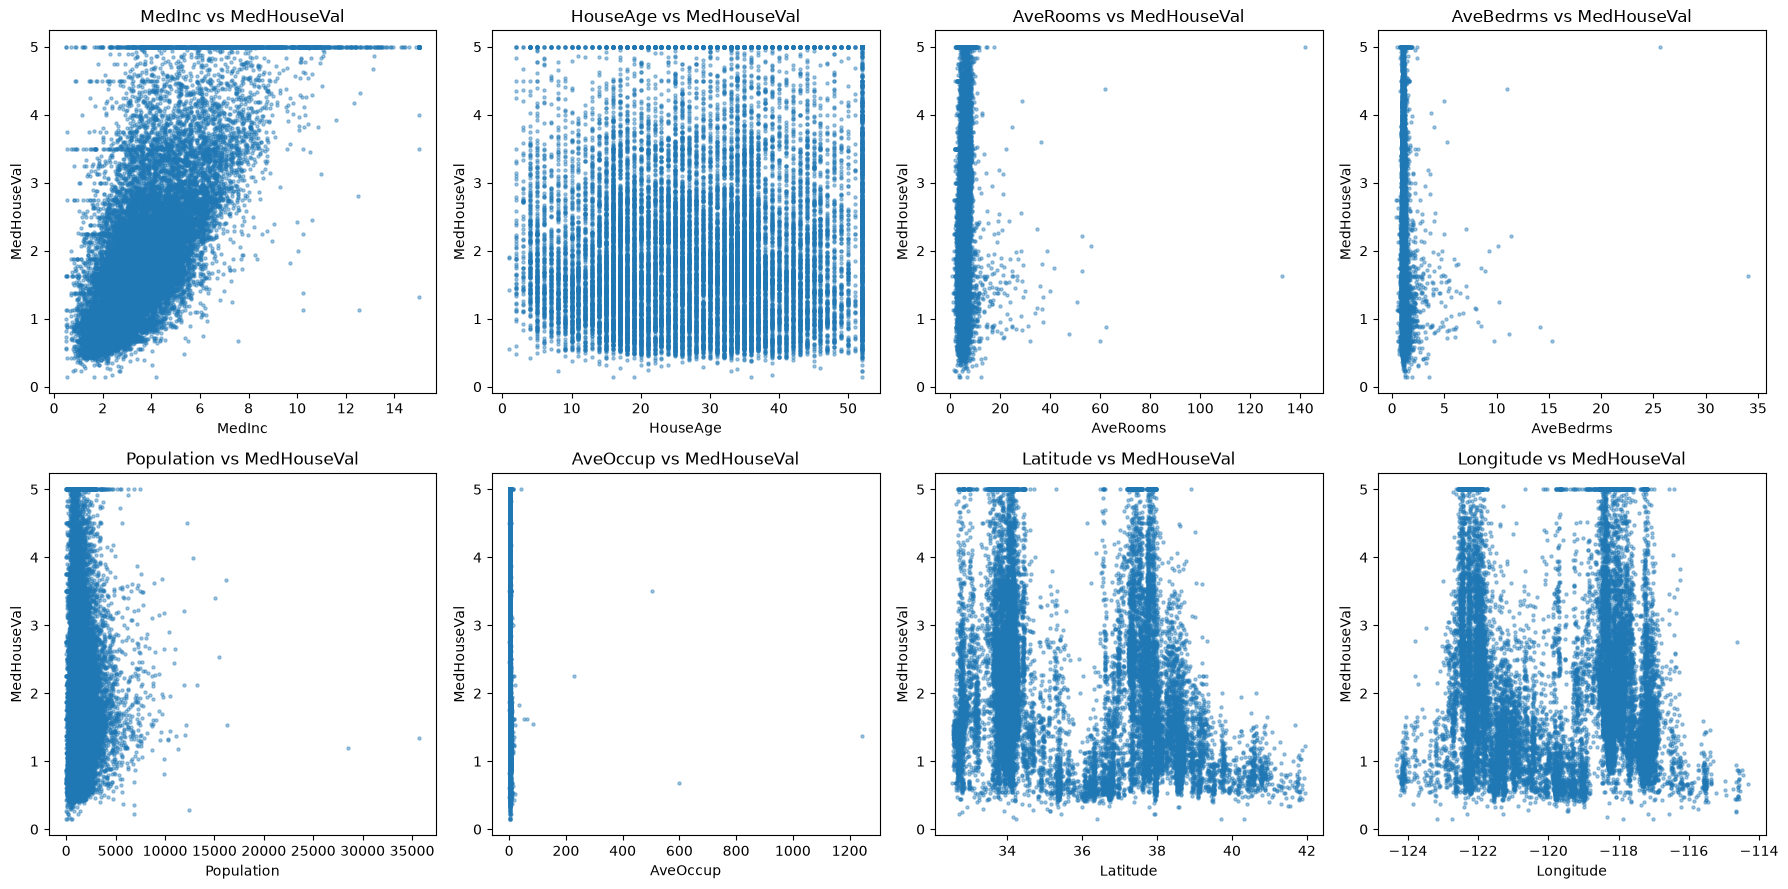

In [29]:
features = df.drop(columns="MedHouseVal").columns

fig, axes = plt.subplots(2, 4, figsize=(18, 9))

for feature, ax in zip(features, axes.flat):
    ax.scatter(df[feature], df["MedHouseVal"], alpha=0.4, s=5)
    ax.set_xlabel(feature)
    ax.set_ylabel("MedHouseVal")
    ax.set_title(f"{feature} vs MedHouseVal")

plt.tight_layout()
plt.show()

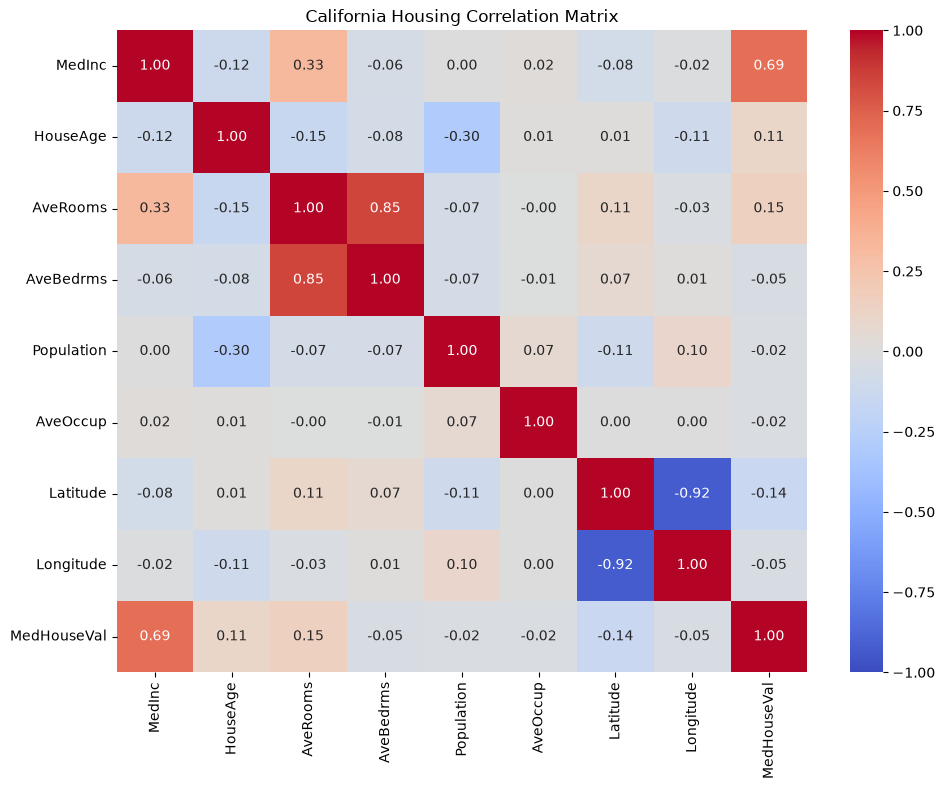

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

corr_matrix = df.corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("California Housing Correlation Matrix")
plt.tight_layout()
plt.show()

In [32]:
# MedInc: MedHouseVal tends to increase with higher medinc, 
# but the relationship doesn't lean towards linear nor it's 100% accurate, some have max medinc with low medhouseval.
# HouseAge: No clear pattern here.
# AveRooms: having lower rooms tends to increase MedHouseVal.
# AveBedrms: having lower bedrooms tends to increase MedHouseVal.
# Population: having lower population tends to increase MedHouseVal.
# AveOccup: having lower occupation tend to increase MedHouseVal.
# Latitude: No clear pattern here.
# Longitude: No clear pattern here.

In [33]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [34]:
models = {
    "Dummy": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),

    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge())
    ]),

    "Lasso": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(max_iter=10000))
    ]),

    "Decision Tree": DecisionTreeRegressor(random_state=42),

    "Random Forest": RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    )
}

In [35]:
param_grids = {
    "Ridge": {
        "model__alpha": [0.1, 1.0, 10.0, 100.0]
    },

    "Lasso": {
        "model__alpha": [0.001, 0.01, 0.1, 1.0]
    },

    "Decision Tree": {
        "max_depth": [None, 5, 10, 20],
        "min_samples_leaf": [1, 5, 10]
    },

    "Random Forest": {
        "n_estimators": [100, 200],
        "max_depth": [None, 10, 20],
        "min_samples_leaf": [1, 5]
    }
}

In [36]:
from sklearn.model_selection import cross_val_score

cv_results = []

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean CV MAE": -scores.mean(),
        "Std CV MAE": scores.std()
    })

cv_df = pd.DataFrame(cv_results).sort_values("Mean CV MAE")

cv_df

,Model,Mean CV MAE,Std CV MAE
5,Random Forest,0.334943,0.005427
4,Decision Tree,0.472372,0.017891
2,Ridge,0.529056,0.009381
1,Linear Regression,0.529061,0.009383
3,Lasso,0.913915,0.010082
0,Dummy,0.913915,0.010082


In [38]:
grid_searches = {}
grid_results = []

for name, param_grid in param_grids.items():
    model = models[name]

    grid = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        scoring="neg_mean_absolute_error",
        cv=cv,
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    grid_searches[name] = grid

    grid_results.append({
        "Model": name,
        "Best CV MAE": -grid.best_score_,
        "Best Parameters": grid.best_params_
    })

grid_df = pd.DataFrame(grid_results).sort_values("Best CV MAE")

grid_df

,Model,Best CV MAE,Best Parameters
3,Random Forest,0.333861,"{'max_depth': None, 'min_samples_leaf': 1, 'n_..."
2,Decision Tree,0.415207,"{'max_depth': None, 'min_samples_leaf': 10}"
0,Ridge,0.529021,{'model__alpha': 10.0}
1,Lasso,0.529115,{'model__alpha': 0.001}


In [39]:
baseline_results = cv_df[
    cv_df["Model"].isin(["Dummy", "Linear Regression"])
][["Model", "Mean CV MAE"]].rename(
    columns={"Mean CV MAE": "CV MAE"}
)

tuned_results = grid_df[
    ["Model", "Best CV MAE"]
].rename(
    columns={"Best CV MAE": "CV MAE"}
)

comparison_df = pd.concat(
    [baseline_results, tuned_results],
    ignore_index=True
).sort_values("CV MAE").reset_index(drop=True)

comparison_df

,Model,CV MAE
0,Random Forest,0.333861
1,Decision Tree,0.415207
2,Ridge,0.529021
3,Linear Regression,0.529061
4,Lasso,0.529115
5,Dummy,0.913915


In [40]:
# Retrieve the best tuned Random Forest
best_model = grid_searches["Random Forest"].best_estimator_

# Predict house values for the test set
y_pred = best_model.predict(X_test)

# Evaluate final predictions
final_results = {
    "Model": "Random Forest",
    "Test MAE": mean_absolute_error(y_test, y_pred),
    "Test RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
    "Test R²": r2_score(y_test, y_pred)
}

pd.DataFrame([final_results])

,Model,Test MAE,Test RMSE,Test R²
0,Random Forest,0.326793,0.504288,0.805933


In [41]:
y_train_pred = best_model.predict(X_train)

train_mae = mean_absolute_error(y_train, y_train_pred)
test_mae = mean_absolute_error(y_test, y_pred)

print("Training MAE:", train_mae)
print("Test MAE:", test_mae)

Training MAE: 0.1210746039395597
Test MAE: 0.32679252083333354


In [42]:
# Signs of overfitting ! (Train MAE is much more smaller than Test MAE)

In [43]:
grid_searches["Random Forest"].best_params_

{'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}

In [45]:
# max_depth and min_samples_leaf may make the Forest build 
# too specific patterns.

In [47]:
rf_param_grid = {
    "n_estimators": [200],
    "max_depth": [10, 15, 20, 30],
    "min_samples_leaf": [2, 5, 10, 20]
}

rf_grid = GridSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),
    param_grid=rf_param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Best CV MAE:", -rf_grid.best_score_)
print("Best parameters:", rf_grid.best_params_)

Best CV MAE: 0.33307091766994185
Best parameters: {'max_depth': 30, 'min_samples_leaf': 2, 'n_estimators': 200}


In [48]:
best_rf = rf_grid.best_estimator_

y_train_pred_rf = best_rf.predict(X_train)
y_pred_rf = best_rf.predict(X_test)

print(
    "Training MAE:",
    mean_absolute_error(y_train, y_train_pred_rf)
)
print(
    "Test MAE:",
    mean_absolute_error(y_test, y_pred_rf)
)

Training MAE: 0.1440839743920687
Test MAE: 0.3260068248298107


In [49]:
# Let's check how important each feature is to our Random Forest model.

In [50]:
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_rf.feature_importances_
}).sort_values("Importance", ascending=False)

importance_df

,Feature,Importance
0,MedInc,0.535582
5,AveOccup,0.138033
6,Latitude,0.088352
7,Longitude,0.087858
1,HouseAge,0.053330
2,AveRooms,0.042259
4,Population,0.028027
3,AveBedrms,0.026559


In [51]:
# Let's check how much each feature affects our model's prediction error.

In [52]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    best_rf,
    X_train,
    y_train,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
}).sort_values("Importance", ascending=False)

permutation_df

,Feature,Importance,Std
0,MedInc,0.629468,0.006403
6,Latitude,0.439446,0.002011
7,Longitude,0.384329,0.001089
5,AveOccup,0.287982,0.000828
1,HouseAge,0.129101,0.002471
2,AveRooms,0.101435,0.001008
3,AveBedrms,0.052392,0.000604
4,Population,0.046617,0.000386


In [53]:
residuals = y_test - y_pred_rf

residuals

20046   -0.016668
3024    -0.294222
15663    0.115582
20484   -0.371944
9814     0.507637
           ...   
15362    0.368000
16623    0.641666
18086    0.186392
2144     0.014711
3665    -0.124050
Name: MedHouseVal, Length: 4128, dtype: float64

In [54]:
# Let's check the distribution of our model's prediction errors.

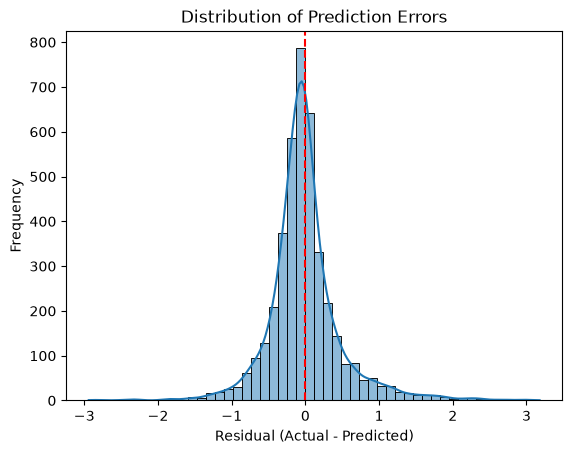

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(residuals, bins=50, kde=True)

plt.axvline(0, color="red", linestyle="--")
plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Errors")
plt.show()

In [56]:
# Analyze the distribution of prediction errors (residuals) to check
# for bias, skewness, and unusually large errors.

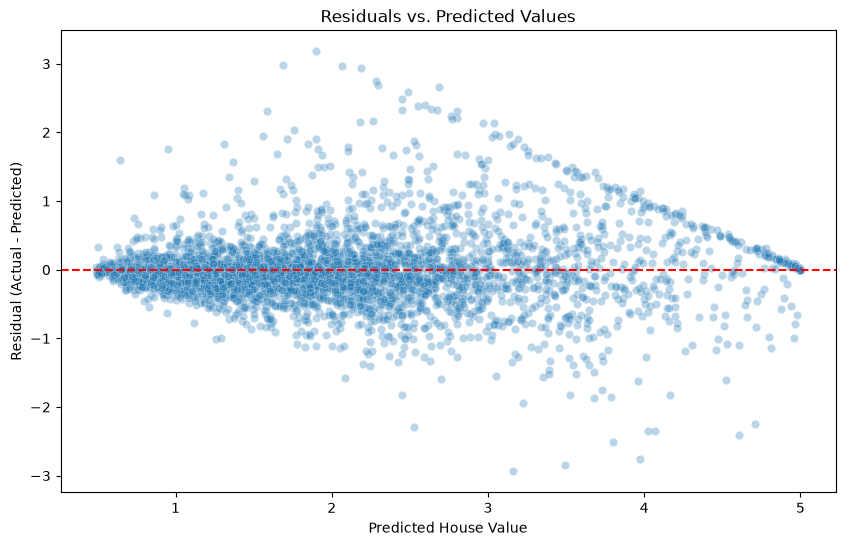

In [57]:
# Check whether prediction errors change depending on predicted house value.

plt.figure(figsize=(10, 6))

sns.scatterplot(x=y_pred, y=residuals, alpha=0.3)

plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted House Value")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residuals vs. Predicted Values")
plt.show()

In [58]:
# The residual plot shows a diagonal pattern at the upper end of predicted values.
# This may be caused by the target variable MedHouseVal being capped at 5.0.

In [59]:
rf_final_results = {
    "Model": "Random Forest",
    "Test MAE": mean_absolute_error(y_test, y_pred_rf),
    "Test RMSE": np.sqrt(mean_squared_error(y_test, y_pred_rf)),
    "Test R²": r2_score(y_test, y_pred_rf)
}

pd.DataFrame([rf_final_results])

,Model,Test MAE,Test RMSE,Test R²
0,Random Forest,0.326007,0.503828,0.806288


In [ ]:
# ## Conclusions

# The goal of this project was to explore the California Housing dataset and develop a machine learning model to predict median house values.

# After exploratory data analysis, several regression models were compared using 5-fold cross-validation. Hyperparameter tuning was then performed to improve model generalization and reduce overfitting.

# The tuned Random Forest was selected as the final model. On the held-out test set, it achieved:

# - **MAE:** 0.326007, equivalent to approximately $32,600.
# - **RMSE:** 0.503828, equivalent to approximately $50,400.
# - **R²:** 0.806288.

# These results indicate that the model captures a substantial amount of variation in median house values. However, its predictions can still have considerable errors, particularly for individual observations.

# Feature importance analysis identified median income (`MedInc`), location (`Latitude` and `Longitude`), and average occupancy (`AveOccup`) as important predictive features.

# Residual analysis also revealed a diagonal pattern associated with the dataset's target-value cap at 5.0, equivalent to $500,000. This cap limits the model's ability to learn differences between houses whose recorded target values have reached the maximum.

# Overall, the project demonstrates a complete regression workflow, from exploratory data analysis and model comparison to hyperparameter tuning, evaluation, and interpretation.
